# Predicción de Pokémon legendarios

## Definición del problema
- **Target:** `is_legendary` (1 = legendario, 0 = no legendario)
- **Tipo de problema:** clasificación binaria
- **Features:** stats de combate (hp, attack, defense, sp_attack, sp_defense, speed), altura, peso, generación, base_happiness y tipos (codificados como dummies).
- **¿Por qué los datos podrían servir?** En el EDA de la Tarea 1 observamos que los legendarios tienen stats de combate considerablemente más altos que el resto. Además, la mayoría de los no legendarios tiene base_happiness = 70, mientras que los legendarios suelen tener valores distintos. Esto sugiere que las features contienen información crucial que separa ambas clases.
- **Algoritmo:** Random Forest (bagging). Lo elegimos porque captura relaciones no lineales entre features, un legendario se caracteriza por tener varios stats altos a la vez, no necesita escalar los datos, acepta NaN de forma nativa y, al promediar muchos árboles entrenados con muestras bootstrap distintas, reduce el sobreajuste que tendría un árbol de decisión individual.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [2]:
PokemonSet = pd.read_csv('pokemon.csv')
target = PokemonSet['is_legendary']

In [3]:
porcentaje_legendarios = target.mean() * 100

print(f"Porcentaje de legendarios: {porcentaje_legendarios:.2f}%")

Porcentaje de legendarios: 8.74%


### Importante

Para que el algoritmo realice un mejor trabajo, filtramos los features que tiene el DataSet. En este caso eliminamos los siguientes features que no aportan información relevante (según criterio propio):
- name
- japanese_name
- pokedex_number
- classification
- against_? 

Además, debido a que abilities es un string que contiene una o más habilidades por pokemones, es una feature un poco más difícil de trabajar, por lo que optamos por eliminarla del DataSet:
- abilities

También eliminamos el feature que nos dice directamente si el pokemon es legendario (pero se utilizará para validar los resultados, por eso se guardó la variable 'target'):
- is_legendary

Eliminamos los siguientes 4 features debido a que en el trabajo anterior se determinó que estas están directamente relacionadas con los pokemones legendarios (concentran a los legendarios dentro de unos rangos pequeños), evitando así hacer "trampa" con el modelo y determinar si es que se puede predecir correctamente utilizando las demás features:
- capture_rate
- percentage_male
- base_egg_steps 
- experience_growth

Eliminamos la siguiente feature debido a que es la suma de otras features, por lo que la vuelve redundante para el modelo:
- base_total

Mantenemos base_happiness en el modelo, aunque sospechamos que también podría ser un atributo de diseño del juego relacionado con ser legendario. Evaluamos su efecto en la sección de experimento.

In [4]:
PokemonSet = PokemonSet.drop(['name', 
                            'japanese_name', 
                            'pokedex_number',
                            'classfication',
                            'against_fire',
                            'against_water',
                            'against_electric',
                            'against_grass',
                            'against_ice',
                            'against_fight',
                            'against_poison',
                            'against_ground',
                            'against_flying',
                            'against_psychic',
                            'against_bug',
                            'against_rock',
                            'against_ghost',
                            'against_dragon',
                            'against_dark',
                            'against_steel',
                            'against_fairy',
                            'against_normal',
                            'is_legendary',
                            'capture_rate',
                            'percentage_male',
                            'base_egg_steps',
                            'abilities',
                            'experience_growth',
                            'base_total'],
                            axis=1)

PokemonSet

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation
0,49,70,49,0.7,45,65,65,45,grass,poison,6.9,1
1,62,70,63,1.0,60,80,80,60,grass,poison,13.0,1
2,100,70,123,2.0,80,122,120,80,grass,poison,100.0,1
3,52,70,43,0.6,39,60,50,65,fire,NaN,8.5,1
4,64,70,58,1.1,58,80,65,80,fire,NaN,19.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,steel,flying,999.9,7
797,181,0,131,0.3,59,59,31,109,grass,steel,0.1,7
798,101,0,53,5.5,223,97,53,43,dark,dragon,888.0,7
799,107,0,101,2.4,97,127,89,79,psychic,NaN,230.0,7


Las variables que corresponden a características cualitativas deben de convertirse en valores numéricos para poder ser analizados, así que convertimos las variables 'type1' y 'type2' en una matriz que represente con '1' al tipo de pokemon que si corresponde, y '0' al tipo que no (de esta forma eliminamos los NaN's de la tabla de datos).

In [5]:
tipos = (pd.get_dummies(PokemonSet['type1'], dtype=int)
           .add(pd.get_dummies(PokemonSet['type2'], dtype=int), fill_value=0)
           .astype(int)
           .add_prefix('tipo_'))

PokemonSet = pd.concat([PokemonSet.drop(columns=['type1', 'type2']), tipos], axis=1)

In [6]:
PokemonSet

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,weight_kg,generation,tipo_bug,tipo_dark,tipo_dragon,tipo_electric,tipo_fairy,tipo_fighting,tipo_fire,tipo_flying,tipo_ghost,tipo_grass,tipo_ground,tipo_ice,tipo_normal,tipo_poison,tipo_psychic,tipo_rock,tipo_steel,tipo_water
0,49,70,49,0.7,45,65,65,45,6.9,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,62,70,63,1.0,60,80,80,60,13.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,100,70,123,2.0,80,122,120,80,100.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,52,70,43,0.6,39,60,50,65,8.5,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,64,70,58,1.1,58,80,65,80,19.0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,999.9,7,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
797,181,0,131,0.3,59,59,31,109,0.1,7,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
798,101,0,53,5.5,223,97,53,43,888.0,7,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
799,107,0,101,2.4,97,127,89,79,230.0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


En el caso de los NaN's que se obtienen en la altura y peso, los dejaremos tal cual como están, pues aunque ya sabemos del EDA que este es un error del DataSet debido a que mezcla las características de un pokemon original con alguna variación suya, no queremos modificar mucho los datos que recibimos. De esta manera nos ajustamos mejor a un caso realista en el que podría haber también un error en los datos recolectados. Random Forest acepta valores NaN de forma nativa.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

In [8]:
PokemonSet.shape

(801, 28)

In [9]:
features = PokemonSet

## Separación entrenamiento / test
Separamos 75% para entrenamiento y 25% para test. Usamos stratify para mantener la proporción de legendarios (8.74%) en ambos conjuntos. El conjunto de test no se usa hasta la evaluación final.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    features, target,
    test_size=0.25,
    stratify=target,
    random_state=42
)

print(f"Train: {len(X_train)} pokémon, {y_train.sum()} legendarios")
print(f"Test:  {len(X_test)} pokémon, {y_test.sum()} legendarios")

Train: 600 pokémon, 52 legendarios
Test:  201 pokémon, 18 legendarios


In [11]:
model = RandomForestClassifier(random_state=42)

model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

In [13]:
scoring = {'f1': 'f1',
           'precision': 'precision',
           'recall': 'recall'}

## Elección de hiperparámetros
Buscamos hiperparámetros con validación cruzada (GridSearchCV) usando **solo el conjunto de entrenamiento**, para que el test no influya en la elección.

In [14]:
parameters = {'max_features':['sqrt', 4, None],
              'n_estimators':[100, 200, 500],
              'min_samples_split': [2, 5, 10], 
              'min_samples_leaf': [1, 2, 4],
              'class_weight': [None, 'balanced_subsample']}

In [15]:
grid = GridSearchCV(
    estimator=model,
    param_grid=parameters,
    cv=cv,
    scoring=scoring,
    refit='f1',
    return_train_score=True,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 162 candidates, totalling 810 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [None, 'balanced_subsample'], 'max_features': ['sqrt', 4, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionc

In [16]:
print(grid.best_params_)

{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [17]:
scoresGrid = pd.DataFrame(grid.cv_results_)
scoresCV = (scoresGrid[['params', 'mean_test_f1', 'std_test_f1',
                        'mean_test_recall', 'mean_test_precision', 'mean_train_f1']]
            .sort_values(by='mean_test_f1', ascending=False))

In [18]:
scoresCV

,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_train_f1
55,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_e...",0.825795,0.078537,0.789091,0.879596,1.000000
57,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_e...",0.822995,0.098097,0.790909,0.881818,0.995121
58,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_e...",0.820074,0.101820,0.770909,0.897778,0.995121
65,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_e...",0.815225,0.111688,0.770909,0.894444,0.955854
68,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_e...",0.815225,0.111688,0.770909,0.894444,0.950735
...,...,...,...,...,...,...
48,"{'class_weight': None, 'max_features': 4, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_esti...",0.496154,0.143085,0.349091,0.960000,0.772206
51,"{'class_weight': None, 'max_features': 4, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_est...",0.496154,0.143085,0.349091,0.960000,0.765040
50,"{'class_weight': None, 'max_features': 4, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_esti...",0.496154,0.143085,0.349091,0.960000,0.775856
110,"{'class_weight': 'balanced_subsample', 'max_features': 4, 'min_samples_leaf': 1, 'min_samples_sp...",0.495800,0.046240,0.365455,0.836190,1.000000


La mejor combinación usa max_features=None (cada árbol considera todas las features en cada división) y n_estimators=200. En validación cruzada obtiene F1 = 0.825 en validación y 1.00 en entrenamiento, lo que ya anticipa que el modelo memoriza el conjunto de entrenamiento.

## Modelo final y evaluación
El modelo final es el mejor estimador del grid, reentrenado con todo el conjunto de entrenamiento. Lo evaluamos en train y en test.

Métrica principal: F1 de la clase legendaria. Como solo el 8.74% de los pokémon son legendarios, accuracy sería engañosa: un modelo que nunca predice "legendario" acertaría en todos los no legendarios y tendría una accuracy muy alta sin detectar ningún legendario. F1 combina precisión (de los predichos como legendarios, cuántos lo son) y recall (de los legendarios reales, cuántos detecta).

In [19]:
best_model = grid.best_estimator_

pred_train = best_model.predict(X_train)
pred_test = best_model.predict(X_test)

resultados_base = pd.DataFrame({
    'f1':        [f1_score(y_train, pred_train),        f1_score(y_test, pred_test)],
    'precision': [precision_score(y_train, pred_train), precision_score(y_test, pred_test)],
    'recall':    [recall_score(y_train, pred_train),    recall_score(y_test, pred_test)]
}, index=['train', 'test'])

resultados_base.round(3)

,f1,precision,recall
train,1.000,1.000,1.000
test,0.765,0.812,0.722


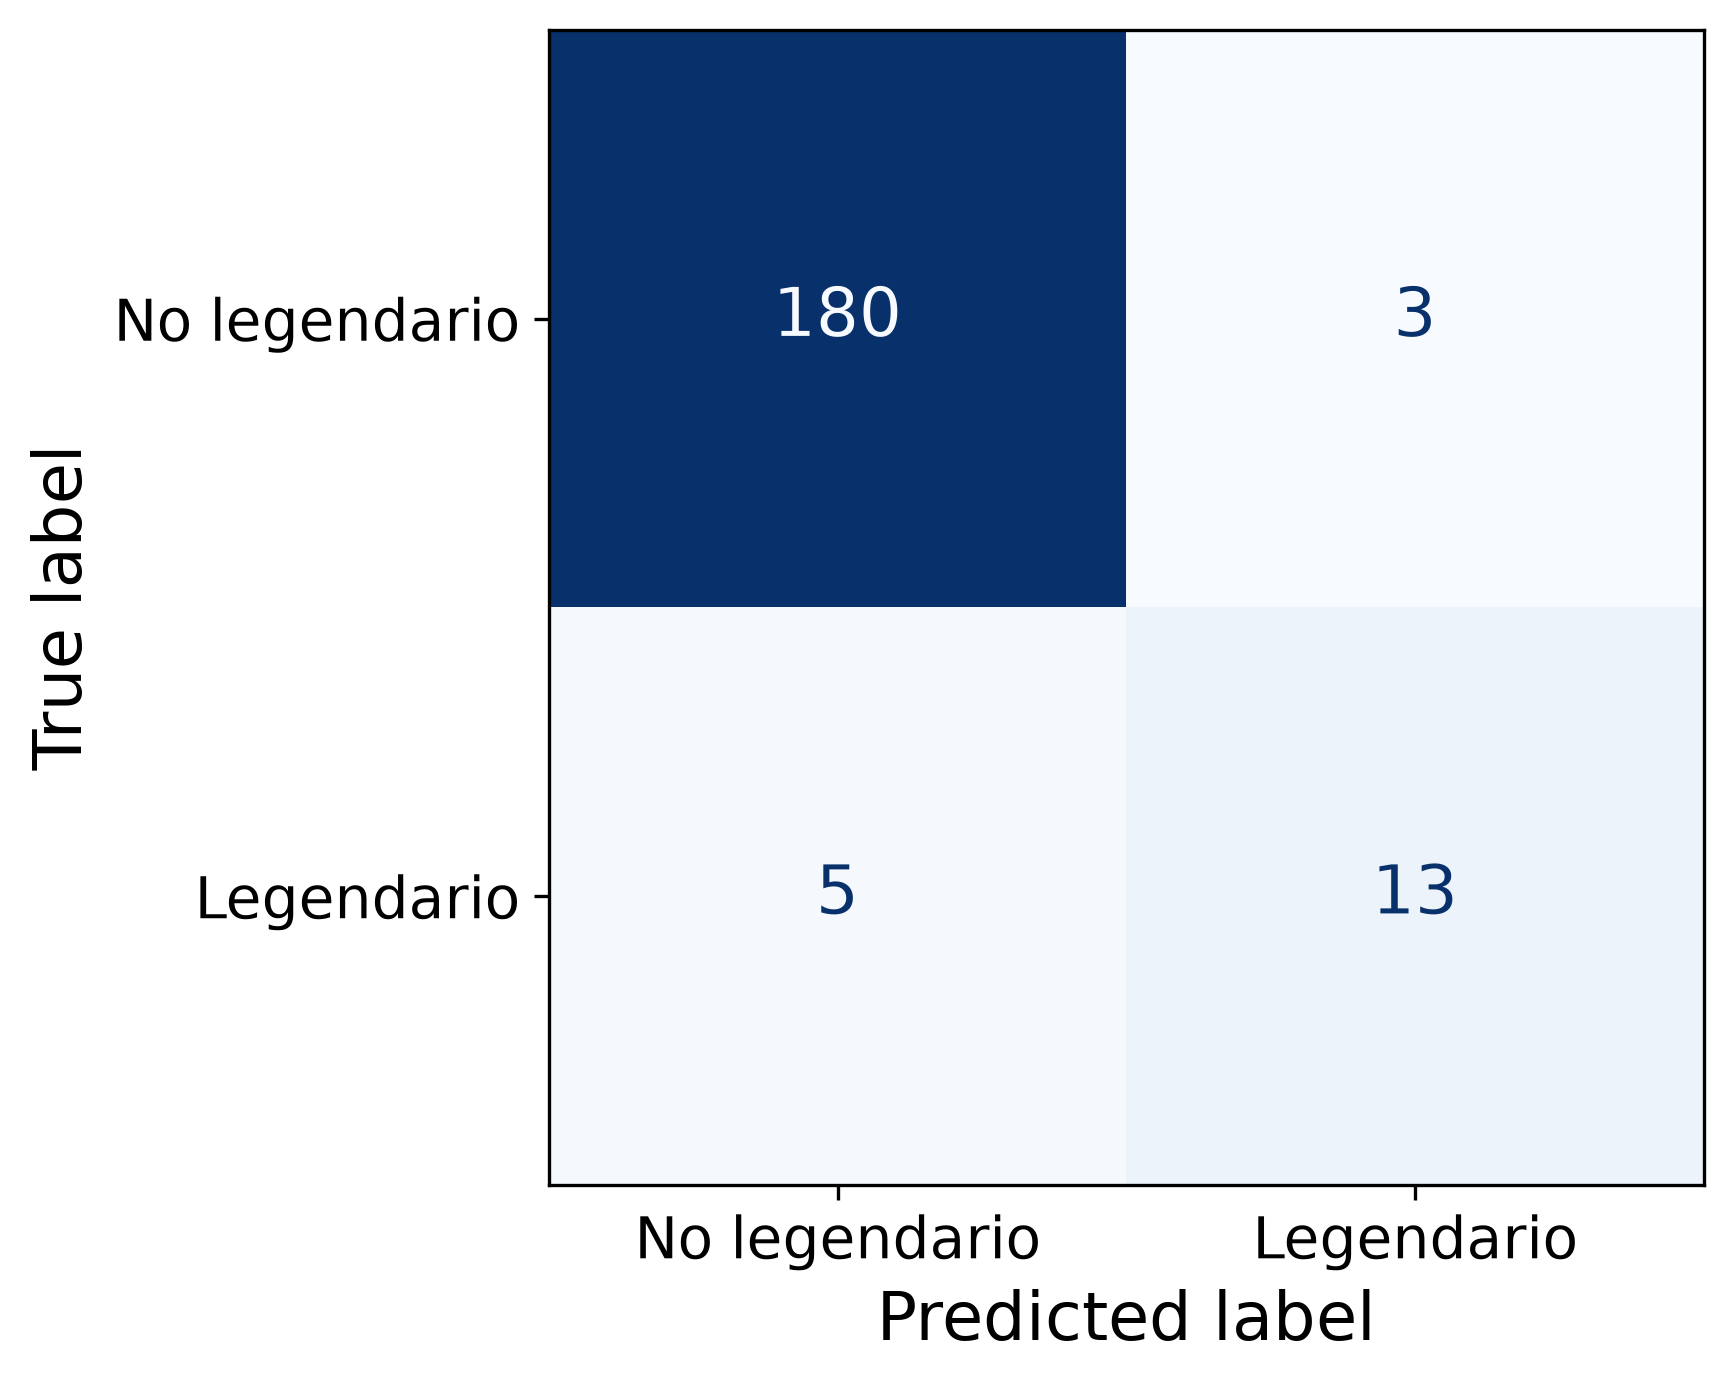

In [20]:
cm = confusion_matrix(y_test, pred_test)

fig, ax = plt.subplots(figsize=(5, 5))
display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                 display_labels=['No legendario', 'Legendario'])
display.plot(ax=ax, cmap='Blues', colorbar=False)
plt.show()

En test, el modelo detecta 13 de los 18 legendarios (recall 0.72) y se equivoca en 3 de los 183 no legendarios. De los 16 pokémon que predice como legendarios, 13 lo son (precision 0.81).

In [21]:
importancias = pd.Series(best_model.feature_importances_, index=features.columns).sort_values(ascending=False)
importancias.head(10)

base_happiness    0.626920
hp                0.058567
attack            0.050762
speed             0.046840
sp_attack         0.045391
weight_kg         0.044851
sp_defense        0.024747
tipo_normal       0.024739
defense           0.014270
tipo_fairy        0.014205
dtype: float64

## Experimento: eliminar base_happiness

### Predicción

base_happiness concentra más de la mitad de la importancia del modelo, de la tarea anterior vimos que la mayoría de los no legendarios tiene un valor de 70, mientras que los legendarios pueden tomar otros valores. Se espera que al eliminar este feature del modelo, este pierda su principal criterio para separar, por lo que la métrica recall en test debería de bajar considerablemente, es decir, dejaría de detectar varios legendarios. En entrenamiento se espera que el F1 siga alto, porque un modelo de Random Forest sin límite de profundidad puede memorizar los datos de entrenamiento perfectamente. Esperamos que aumente la brecha entre train y test.

In [22]:
X_train_exp = X_train.drop(columns='base_happiness')
X_test_exp = X_test.drop(columns='base_happiness')

modelo_exp = RandomForestClassifier(**grid.best_params_, random_state=42)
modelo_exp.fit(X_train_exp, y_train)

pred_train_exp = modelo_exp.predict(X_train_exp)
pred_test_exp = modelo_exp.predict(X_test_exp)

resultados_exp = pd.DataFrame({
    'f1':        [f1_score(y_train, pred_train_exp),        f1_score(y_test, pred_test_exp)],
    'precision': [precision_score(y_train, pred_train_exp), precision_score(y_test, pred_test_exp)],
    'recall':    [recall_score(y_train, pred_train_exp),    recall_score(y_test, pred_test_exp)]
}, index=['train', 'test'])

pd.concat({'Con base_happiness': resultados_base,
           'Sin base_happiness': resultados_exp}).round(3)

f1  precision  recall
Con base_happiness train  1.000      1.000   1.000
                   test   0.765      0.812   0.722
Sin base_happiness train  1.000      1.000   1.000
                   test   0.519      0.778   0.389

In [23]:
importancias_exp = pd.Series(modelo_exp.feature_importances_, index=X_train_exp.columns).sort_values(ascending=False)
importancias_exp.head(5)

speed        0.185809
sp_attack    0.178548
weight_kg    0.162670
hp           0.099081
height_m     0.071445
dtype: float64

### Interpretación

La predicción que planteamos se cumplió. Sin base_happiness, el recall en test baja de 0.72 a 0.39, el modelo pasó de detectar 13 a solo 7 de 18 legendarios. El F1 cae a 0.52, mientras que precision no sufre un cambio significativo, el modelo se volvió más conservador, ya que predice menos legendarios pero sigue acertando en los que predice. En train el F1 se mantuvo en 1, así que la brecha entre train y test creció.

Para el caso de sin base_happiness, las features más importantes pasan a ser speed, sp_attack y weight_kg, pero los stats por sí solos no bastan, ya que muchos legendarios tienen stats parecidos a pokémon no legendarios. Esto muestra que gran parte del desempeño del modelo depende de un atributo de diseño del juego más que de características físicas del pokémon, al igual que las 4 features que eliminamos al inicio.

## Auditoría del Modelo

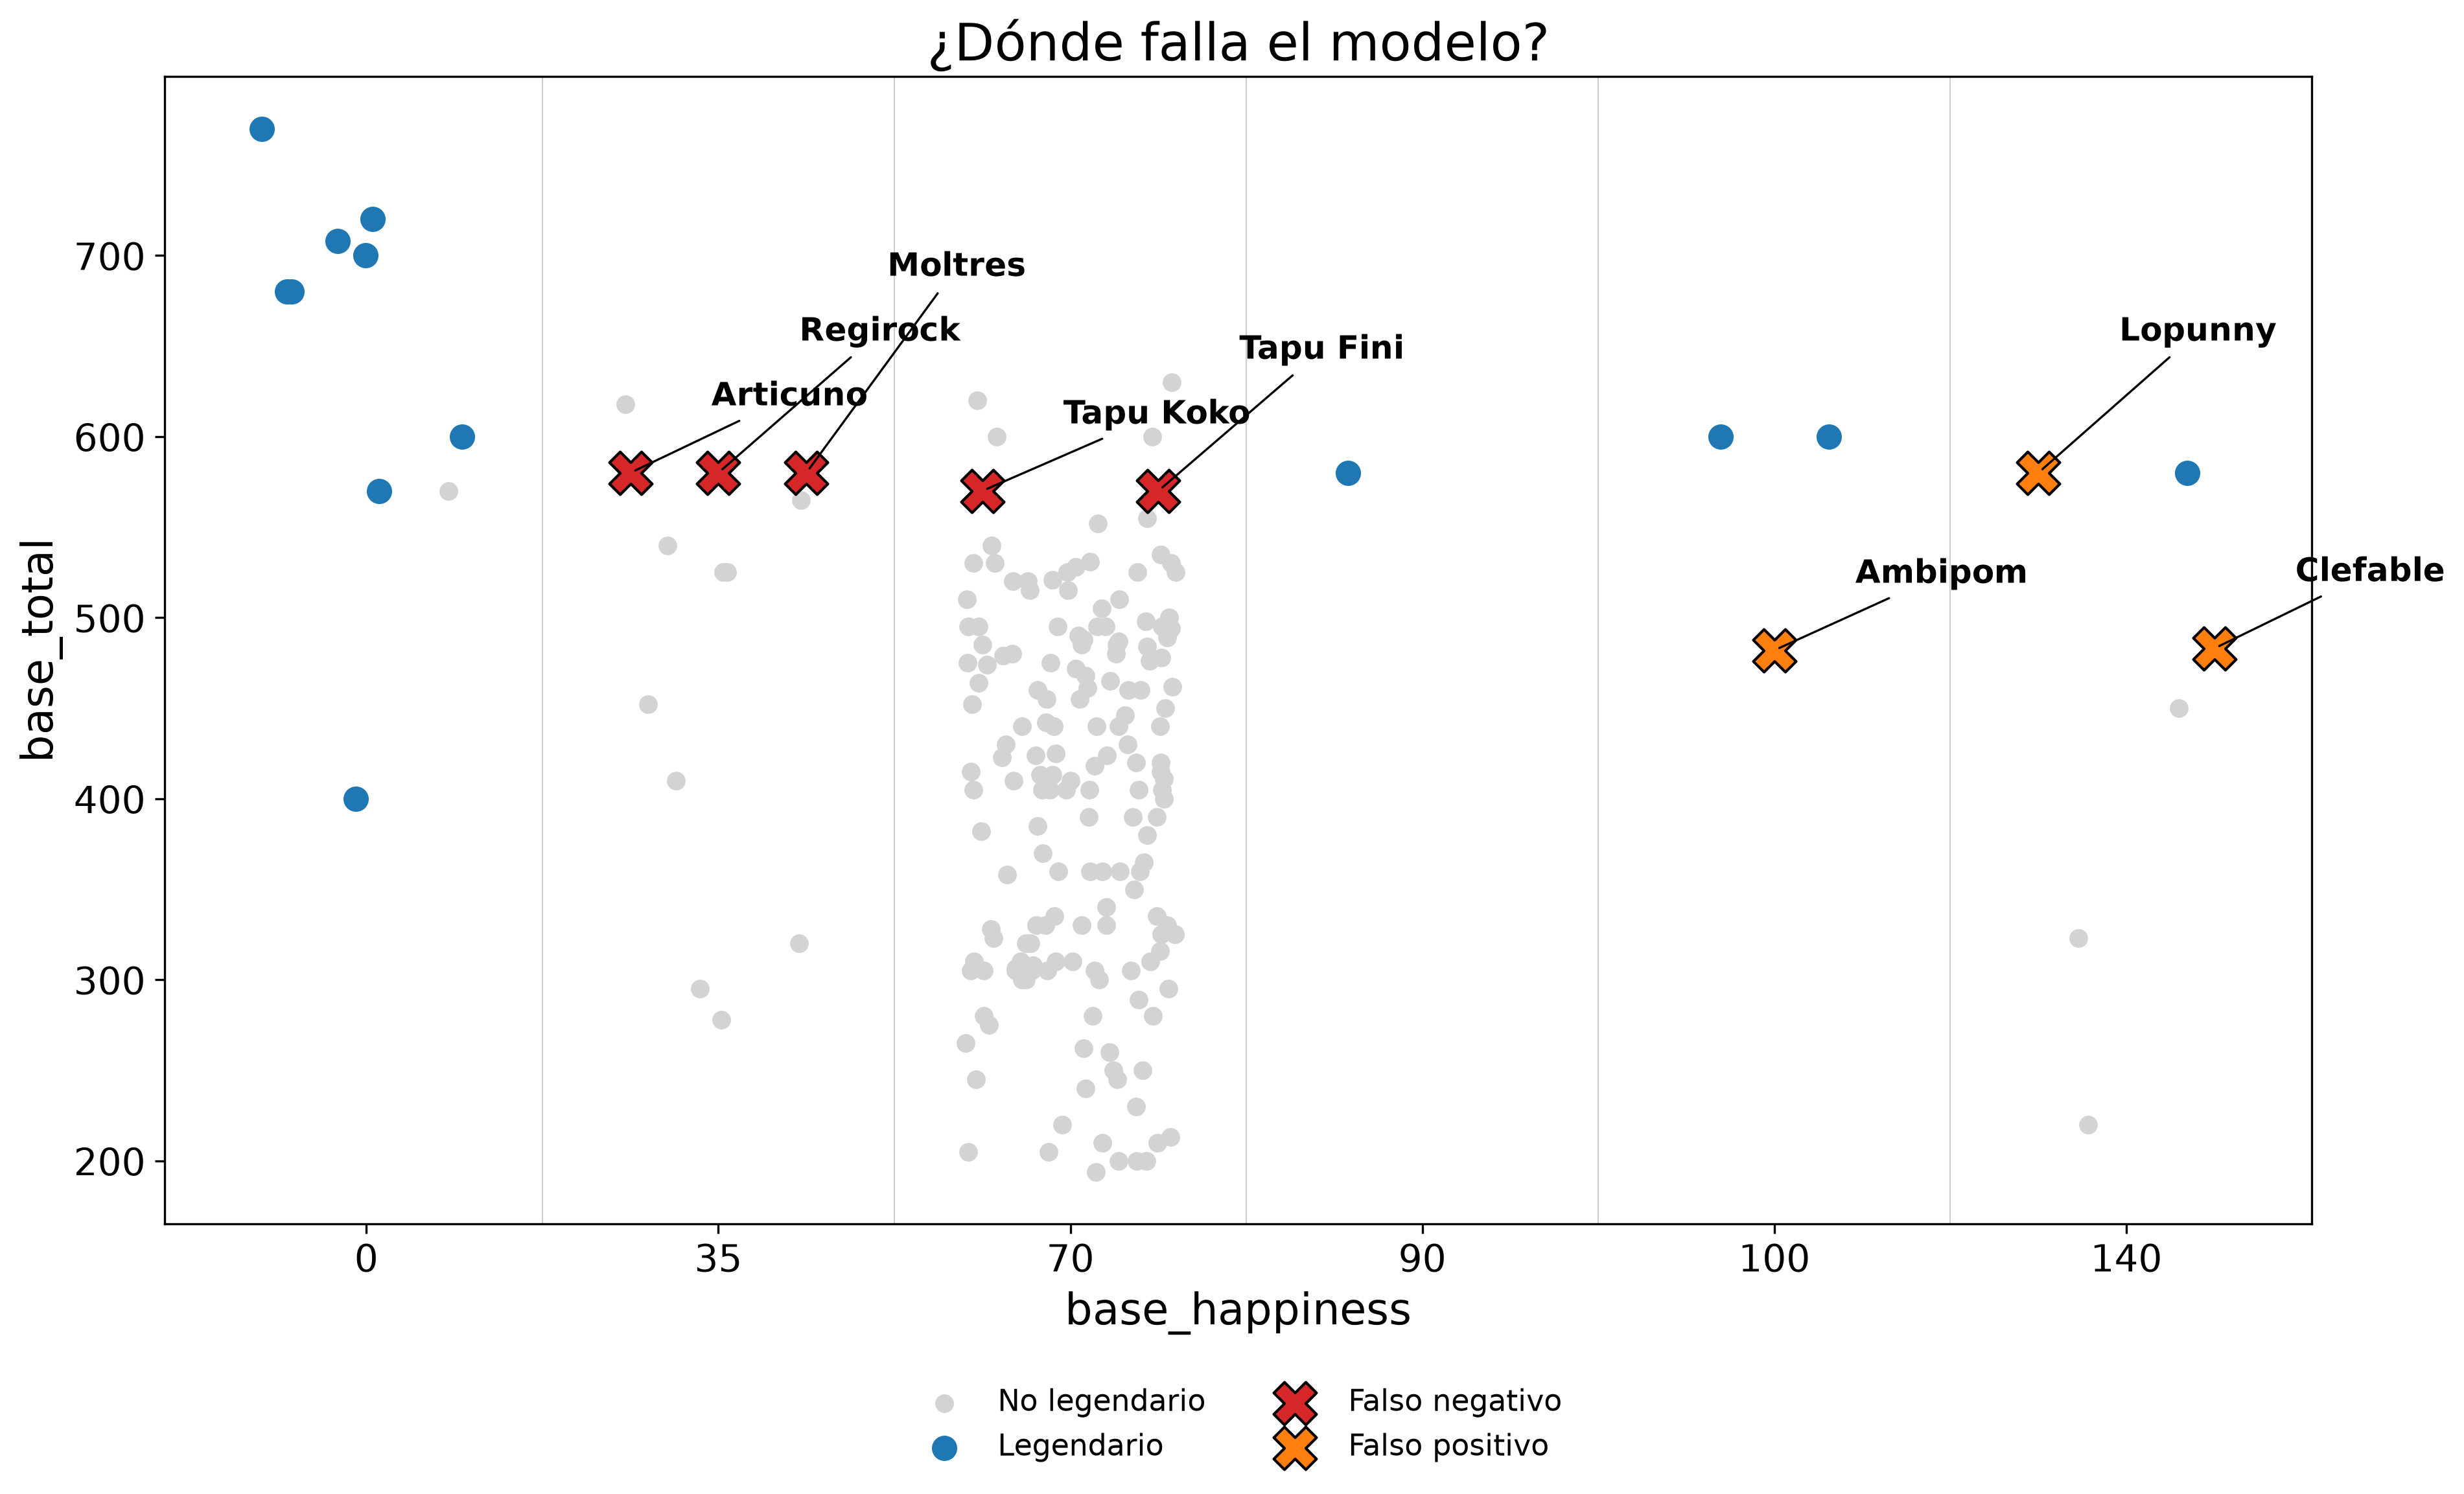

In [24]:
datos_originales = pd.read_csv('pokemon.csv')
test_info = datos_originales.loc[X_test.index, ['name', 'base_total', 'base_happiness']].copy()
test_info['real'] = y_test.values
test_info['pred'] = pred_test

valores = sorted(test_info['base_happiness'].unique())
posicion = {v: i for i, v in enumerate(valores)}
rng = np.random.default_rng(0)
test_info['x'] = test_info['base_happiness'].map(posicion) + rng.uniform(-0.3, 0.3, len(test_info))

es_error = test_info['real'] != test_info['pred']
for v, grupo in test_info[es_error].groupby('base_happiness'):
    if len(grupo) > 1:
        test_info.loc[grupo.index, 'x'] = posicion[v] + np.linspace(-0.25, 0.25, len(grupo))
    else:
        test_info.loc[grupo.index, 'x'] = posicion[v]

ok_no = test_info[(test_info['real'] == 0) & (test_info['pred'] == 0)]
ok_si = test_info[(test_info['real'] == 1) & (test_info['pred'] == 1)]
fp = test_info[(test_info['real'] == 0) & (test_info['pred'] == 1)]
fn = test_info[(test_info['real'] == 1) & (test_info['pred'] == 0)]

fig, ax = plt.subplots(figsize=(13, 8))
ax.scatter(ok_no['x'], ok_no['base_total'], c='lightgray', s=35, label='No legendario')
ax.scatter(ok_si['x'], ok_si['base_total'], c='tab:blue', s=70, label='Legendario')
ax.scatter(fn['x'], fn['base_total'], c='tab:red', marker='X', s=250, edgecolors='black',
           label='Falso negativo')
ax.scatter(fp['x'], fp['base_total'], c='tab:orange', marker='X', s=250, edgecolors='black',
           label='Falso positivo')

errores = pd.concat([fn, fp]).sort_values(['base_happiness', 'base_total'])
errores['k'] = errores.groupby('base_happiness').cumcount()
for _, fila in errores.iterrows():
    ax.annotate(fila['name'], (fila['x'], fila['base_total']),
                xytext=(30, 25 + 24 * fila['k']), textcoords='offset points',
                fontsize=12, fontweight='bold',
                arrowprops=dict(arrowstyle='-', color='black', lw=0.8))

for i in range(len(valores) - 1):
    ax.axvline(i + 0.5, color='gray', linewidth=0.5, alpha=0.4)

ax.set_xticks(range(len(valores)))
ax.set_xticklabels(valores)
ax.set_xlabel('base_happiness')
ax.set_ylabel('base_total')
ax.set_title('¿Dónde falla el modelo?')
ax.legend(fontsize=11, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [25]:
pd.concat([fn, fp])[['name', 'real', 'pred', 'base_total', 'base_happiness']]

,name,real,pred,base_total,base_happiness
784,Tapu Koko,1,0,570,70
143,Articuno,1,0,580,35
376,Regirock,1,0,580,35
145,Moltres,1,0,580,35
787,Tapu Fini,1,0,570,70
423,Ambipom,0,1,482,100
427,Lopunny,0,1,580,140
35,Clefable,0,1,483,140


### 1. ¿Qué tan bien generaliza el modelo?

Hay un claro sobreajuste que puede verse en F1 con 1 en entrenamiento y 0.76 en test. El modelo Random Forest al no tener límite de profundidad memoriza el conjunto de entrenamiento, por lo que el desempeño en train no es revelador. Aún así, el desempeño en test es considerable y coherente con el de validación cruzada, lo que indica que el modelo sí aprendió patrones, aunque con varianza. Además cabe decir que un factor influyente fue la cantidad de legendarios, solo hay 18 legendarios en test.   

### 2. ¿Dónde falla el modelo?
Los 8 errores se explican por base_happiness:
- **Falsos negativos:** Articuno, Moltres y Regirock tienen happiness 35, un valor frecuente en no legendarios. Tapu Koko y Tapu Fini tienen 70, el valor típico de los no legendarios. Sus stats son altas pero similares a los de no legendarios fuertes.
- **Falsos positivos:** Lopunny (140), Clefable (140) y Ambipom (100) no son legendarios, pero tienen valores de happiness poco comunes, distintos de 70. Como el modelo asocia esos valores con ser legendario, los clasificó mal. Lopunny además tiene los stats de su forma Mega (580), por el error del dataset que vimos en el EDA.

### 3. ¿Qué aprendimos que no era evidente con una única métrica?
Un F1 de 0.76 puede considerarse aceptable pero esconde que depende casi por completo de una sola feature (63% de la importancia). El experimento mostró que sin ella el recall cae a la mitad, y el análisis de errores mostró que todos los fallos se explican por esa misma feature. También vimos que el resultado depende del split, el mismo modelo obtiene 0.83 en validación cruzada y 0.76 en este test.

### 4. ¿Cómo mejoraríamos el modelo?
Agregaríamos base_total como feature. Sin base_happiness, el modelo no logra distinguir legendarios usando stats individuales, y un árbol no puede "sumar" columnas por sí solo, base_total le daría directamente una medida del poder total del pokémon, que es la característica más asociada a los legendarios en el EDA. Esto podría reducir la dependencia de base_happiness. También limitaríamos la profundidad de los árboles (max_depth o min_samples_leaf) para reducir la brecha entre train y test.

## Conclusiones

Consideramos que el modelo es bastante confiable pero no perfecto, siguiendo las métricas, tiene una buena precisión, cuando predice que un pokemon es legendario, casi siempre acierta y detecta a los legendarios con stats muy altos. Sus principales limitaciones son que depende fuertemente de una feature (base_happiness), un atributo de diseño del juego y no una característica propia del pokemon. Sin ella detecta 7 de los 18 legendarios, otra limitación que se le atribuye a los datos, al ser una poca cantidad de legendarios las métricas son inestables. El modelo funciona dentro de este dataset, pero no sería confiable para pokémon de nuevas generaciones si los diseñadores cambiaran la forma de asignar base_happiness. Obtener un buen F1 no implica que el modelo haya aprendido qué hace "legendario" a un pokémon.

USO DE IA (no se si poner esto ahi tu me dices jametsin)

en le grafico de ¿Donde falla el modelo?